In [6]:
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import os

In [ ]:
# Mostramos los datos
df_paises = pd.read_csv("../data/paises.csv",sep=";")

In [8]:
df_paises

,CODIGO,PAIS
0,23,ALEMANIA
1,63,ARGENTINA
2,69,AUSTRALIA
3,72,AUSTRIA
4,87,BELGICA
...,...,...
91,863,"VIRGENES, ISLAS (BRITANICAS)"
92,805,TOKELAU
93,141,CAMBOYA (KAMPUCHEA)
94,17,ALBANIA


In [9]:
# Assuming your DataFrame is named 'df'
dict_paises = dict(zip(df_paises['CODIGO'], df_paises['PAIS']))

In [10]:
dict_paises.items()

dict_items([(23, 'ALEMANIA'), (63, 'ARGENTINA'), (69, 'AUSTRALIA'), (72, 'AUSTRIA'), (87, 'BELGICA'), (97, 'BOLIVIA'), (105, 'BRASIL'), (149, 'CANADA'), (169, 'COLOMBIA'), (187, 'COREA NORTE'), (190, 'COREA SUR'), (196, 'C. RICA'), (198, 'CROACIA'), (199, 'CUBA'), (200, 'CUBA'), (211, 'CHILE'), (215, 'CHINA'), (218, 'TAIWAN'), (232, 'DINAMARCA'), (239, 'ECUADOR'), (240, 'EGIPTO'), (242, 'EL SALVADOR'), (245, 'ESPAÑA'), (246, 'ESLOVAQUIA'), (247, 'ESLOVENIA'), (249, 'USA'), (251, 'ESTONIA'), (267, 'FILIPINAS'), (271, 'FINLANDIA'), (275, 'FRANCIA'), (301, 'GRECIA'), (317, 'GUATEMALA'), (345, 'HONDURAS'), (351, 'HONG KONG'), (361, 'INDIA'), (365, 'INDONESIA'), (369, 'IRAK'), (372, 'IRAN'), (375, 'IRLANDA'), (383, 'ISRAEL'), (386, 'ITALIA'), (399, 'JAPON'), (403, 'JORDANIA'), (410, 'KENIA'), (429, 'LETONIA'), (455, 'MALASIA'), (474, 'MARRUECOS'), (493, 'MEXICO'), (521, 'NICARAGUA'), (528, 'NIGERIA'), (538, 'NORUEGA'), (548, 'N. ZELANDA'), (573, 'HOLANDA'), (576, 'PAKISTAN'), (580, 'PANAMA'

In [12]:
# via transporte
df_via_transp = pd.read_csv('../data/via_transporte.csv',sep=";")


In [13]:
df_via_transp

,CODIGO,VIA_TRANSPORTE
0,4,AEREO
1,5,CORREO
2,2,FERREO
3,7,INSTALACIONES DE TRANSPORTE FIJAS
4,1,MARITIMO
5,6,MULTIMODAL
6,9,OTRO MODO DE TRANSPORTE
7,3,TERRESTRE
8,8,VIAS NAVEGABLES INTERIORES


In [15]:
pred_farma = pd.read_pickle("..\modelos\predicciones_nandina\predicciones_Farma.pkl")

<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\3745167382.py:1: SyntaxWarning: invalid escape sequence '\m'
  pred_farma = pd.read_pickle("..\modelos\predicciones_nandina\predicciones_Farma.pkl")


In [16]:
pred_farma.count()

ID                  14775
ID_DEPARIMPO        14775
ID_NANDINA          14775
ID_NITIMPOR         14775
ID_PAISCOMPRA       14775
ID_PAISORIGEN       14775
COD_ADUANA          14775
VIA_TRANSP          14775
ANNIO_PRESENTA      14775
MES_PRESENTA        14775
FECHA_PRESENTA      14775
NANDINA             14775
DESCRIPCIONMERCA    14775
NUM_PREIMP          14775
NUM_ACEPTACION      14775
NITDECLARANTE       14775
NITIMPOR            14775
RAZONIMPOR          14775
EXPORTADOR          14775
CIUPAISEXPOR        14775
PAISPROC            14775
PAISORIGEN          14775
PAISCOMPRA          14775
CANTIDAD            14775
CODUNIDAD           14775
KILOSNETO           14775
KILOSBRUTO          14775
FOBDO               14775
FLETES              14775
CIFDO               14775
FECHAMANIFIESTO     14775
NUMMANIFIESTO       14510
NUMLICENCIA         14023
ANNOLICENCIA        14775
principio activo    14775
fabricante          14775
precio              14775
marca               14775
TIPO_PRODUCT

In [17]:
pred_farma.head()

,ID,ID_DEPARIMPO,ID_NANDINA,ID_NITIMPOR,ID_PAISCOMPRA,ID_PAISORIGEN,COD_ADUANA,VIA_TRANSP,ANNIO_PRESENTA,MES_PRESENTA,...,ANNOLICENCIA,principio activo,fabricante,precio,marca,TIPO_PRODUCTO,principio activo,fabricante,marca,precio
0,16924681.0,18.0,3333.0,87198.0,88.0,65.0,35.0,1.0,2019.0,1.0,...,2019.0,acetico acido,oci intern,0.0,acido acetico glacial,Farma,propilenglicol,jiangsu xinhe,dip susp,-4.284976e+09
1,16924937.0,34.0,3171.0,1259.0,116.0,116.0,35.0,1.0,2019.0,1.0,...,2018.0,sorbitol,kasyap sweetners,56.0,listerine cool mint,Farma,propilenglicol,enaltec,dip susp,-7.982636e+09
2,16925468.0,3.0,3699.0,87705.0,74.0,74.0,35.0,1.0,2019.0,1.0,...,2018.0,l-lisina hcl,sino star chemicals,1198.0,equiforma,Farma,propilenglicol,xinfa pharma,dip susp,-4.284976e+09
3,16925869.0,8.0,4175.0,204523.0,74.0,74.0,35.0,1.0,2019.0,1.0,...,2018.0,c ascorbico acido,yixing jiangshan biotech,496.0,inositol nf12,Farma,b2 riboflavina,xinfa pharma,keytruda 100 mg (mk-3475),1.740436e+09
4,16925878.0,8.0,4170.0,204523.0,74.0,74.0,35.0,1.0,2019.0,1.0,...,2018.0,b1 tiamina hcl,jiangxi tianxin pharma,409.0,inositol nf12,Farma,b2 riboflavina,shanghai tianjia biochemical,keytruda 100 mg (mk-3475),1.740436e+09


In [19]:
modelo_farma = pd.read_pickle('..\modelos\modelos_nandina\modelo_Farma.pkl')

<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\3490310151.py:1: SyntaxWarning: invalid escape sequence '\m'
  modelo_farma = pd.read_pickle('..\modelos\modelos_nandina\modelo_Farma.pkl')


In [20]:
modelo_farma

{'modelo_clas': {'principio activo': LGBMClassifier(n_jobs=-1, random_state=42, verbose=-1),
  'fabricante': LGBMClassifier(n_jobs=-1, random_state=42, verbose=-1),
  'marca': LGBMClassifier(n_jobs=-1, random_state=42, verbose=-1)},
 'modelo_reg': LGBMRegressor(n_jobs=-1, random_state=42, verbose=-1),
 'X_test':        VIA_TRANSP   NITIMPOR     NANDINA  PAISORIGEN  PAISPROC  PAISCOMPRA  \
 10999           1  860000751  2905450000         386       386         573   
 7793            3  890300466  2933599000         361       245         767   
 5165            4  860000760  2938100000         215       245         845   
 5202            4  860000760  2933799000         386       767         845   
 3433            1  860029022  2922509000         215       215         215   
 ...           ...        ...         ...         ...       ...         ...   
 5554            1  900677748  2931909000         249       249         249   
 6422            1  800171809  2909301000         245  

In [21]:
# Limpieza por si hay duplicadas o espacios
pred_farma.columns = pred_farma.columns.str.strip()
pred_farma.columns = pred_farma.columns.str.replace(r"\s+", " ", regex=True)
pred_farma = pred_farma.loc[:, ~pred_farma.columns.duplicated()]

cols_X = ["VIA_TRANSP","NANDINA","PAISORIGEN","PAISPROC","PAISCOMPRA","KILOSNETO","FOBDO","FLETES"]
cols_y = ["principio activo", "fabricante", "precio", "marca"]

X = pred_farma[cols_X]
y = pred_farma[cols_y]

In [22]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15103 entries, 0 to 27439
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   VIA_TRANSP  14775 non-null  float64
 1   NANDINA     14775 non-null  float64
 2   PAISORIGEN  14775 non-null  float64
 3   PAISPROC    14775 non-null  float64
 4   PAISCOMPRA  14775 non-null  float64
 5   KILOSNETO   14775 non-null  float64
 6   FOBDO       14775 non-null  float64
 7   FLETES      14775 non-null  float64
dtypes: float64(8)
memory usage: 1.0 MB


In [23]:
y.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15103 entries, 0 to 27439
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   principio activo  14775 non-null  category
 1   fabricante        14775 non-null  category
 2   precio            14775 non-null  float64 
 3   marca             14775 non-null  category
dtypes: category(3), float64(1)
memory usage: 412.0 KB


### Evaluación del modelo

In [24]:
# Cargar modelo
modelo_precio = modelo_farma["modelo_reg"]
features = modelo_farma["features"]

# Label encoders
label_encoders = modelo_farma.get("label_encoders", None)

# Target de regresión 
target_reg = modelo_farma.get("target_reg", "precio")

X_pred = X.copy()
X_pred = X_pred.reindex(columns=features)

# Aplicar encoders 
if label_encoders is not None:
    for col, encoder in label_encoders.items():
        if col in X_pred.columns:
            try:
                X_pred[col] = encoder.transform(X_pred[col].astype(str))
            except Exception as e:
                print(f"No fue posible transformar la columna {col}: {e}")

y_pred = modelo_precio.predict(X_pred)

# Transformación logaritmica
if "log" in target_reg.lower():    
    y_pred_final = np.expm1(y_pred)
    print("✔ Predicciones convertidas desde log a escala real.")
else:
    y_pred_final = y_pred

print("\nPrimeras predicciones:")
print(y_pred_final[:10])

print("\nRango de predicciones:")
print(f"mín = {y_pred_final.min()}  |  máx = {y_pred_final.max()}")

predicciones_precio = y_pred_final



Primeras predicciones:
[7.19543432e+09 8.29010825e+09 7.19543432e+09 7.60109090e+09
 7.60109090e+09 7.19542588e+09 7.60109935e+09 7.19543432e+09
 7.19543432e+09 7.19543432e+09]

Rango de predicciones:
mín = -19029733959178.824  |  máx = 668666670577589.9


C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\1820987282.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y["precio"] = pd.to_numeric(y["precio"], errors="coerce")


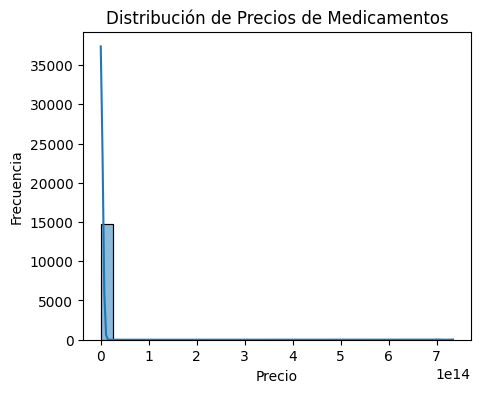

In [25]:
# Curva de residuos estandarizados
y["precio"] = pd.to_numeric(y["precio"], errors="coerce")
plt.figure(figsize=(5,4))
sns.histplot(y["precio"], bins=30, kde=True)
plt.title("Distribución de Precios de Medicamentos")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.show()

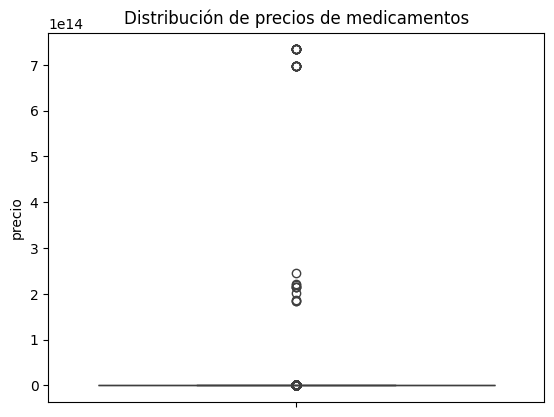

In [26]:
# Distribución valores atípicos
sns.boxplot(y=y["precio"])
plt.title("Distribución de precios de medicamentos")
plt.show()

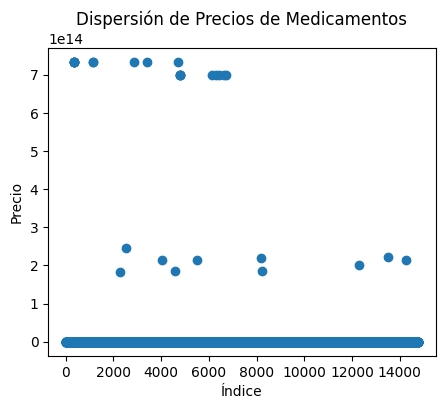

In [27]:
plt.figure(figsize=(5,4))
plt.scatter(y.index, y["precio"])
plt.title("Dispersión de Precios de Medicamentos")
plt.xlabel("Índice")
plt.ylabel("Precio")
plt.show()

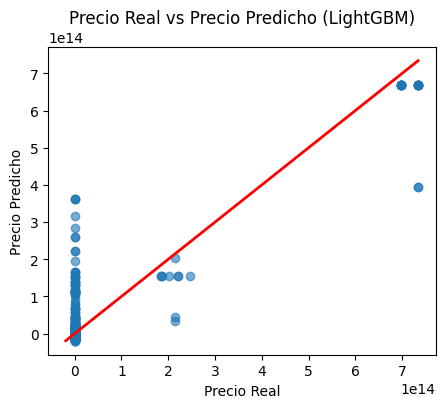

In [28]:
# Valores reales
y_real = y["precio"]

plt.figure(figsize=(5,4))

# Gráfico de dispersión
plt.scatter(y_real, y_pred, alpha=0.6)

# Línea 45° (predicción perfecta)
min_val = min(y_real.min(), y_pred.min())
max_val = max(y_real.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r-', linewidth=2)

plt.title("Precio Real vs Precio Predicho (LightGBM)")
plt.xlabel("Precio Real")
plt.ylabel("Precio Predicho")

plt.show()

### Análisis de resultados

C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\3158201686.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["PAISPROC_NOMBRE"] = X["PAISPROC"].map(map_paises)


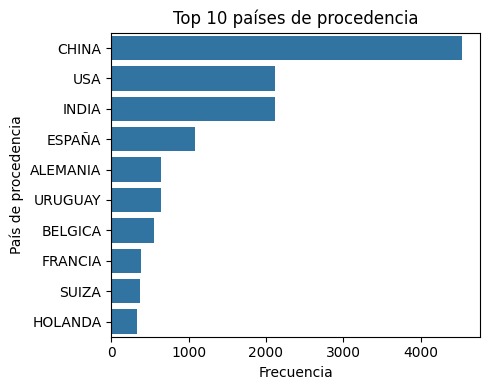

In [29]:
# Diccionario del código al nombre del país
map_paises = df_paises.set_index("CODIGO")["PAIS"].to_dict()

# Crear columna con nombre del país
X["PAISPROC_NOMBRE"] = X["PAISPROC"].map(map_paises)

# Top 10 países
freq = X["PAISPROC_NOMBRE"].value_counts().head(10)

plt.figure(figsize=(5,4))
sns.barplot(x=freq.values, y=freq.index)

plt.title("Top 10 países de procedencia")
plt.xlabel("Frecuencia")
plt.ylabel("País de procedencia")
plt.tight_layout()
plt.show()


C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\2951423055.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["PAISCOMPRA_NOMBRE"] = X["PAISCOMPRA"].map(map_paises)


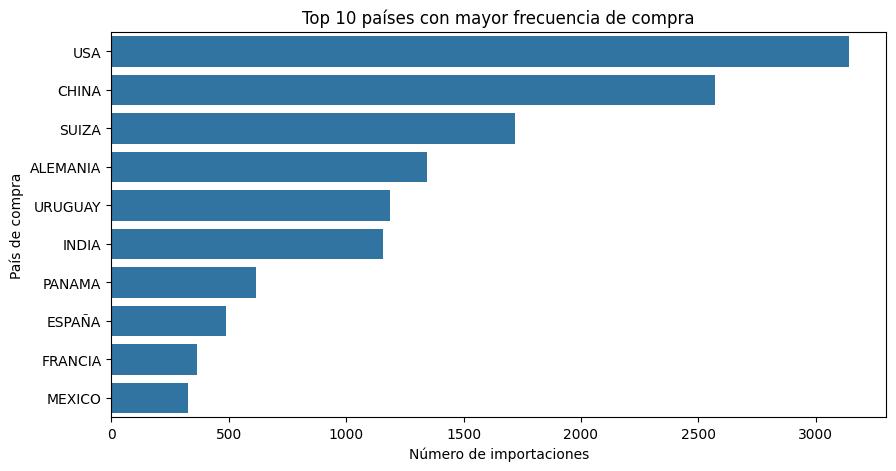

In [30]:
# Crear diccionario de mapeo: código y nombre del país
map_paises = df_paises.set_index("CODIGO")["PAIS"].to_dict()

# Crear columna con el nombre del país
X["PAISCOMPRA_NOMBRE"] = X["PAISCOMPRA"].map(map_paises)

# Obtener los 10 países con mayor frecuencia de compra
top_10 = X["PAISCOMPRA_NOMBRE"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(
    x=top_10.values,
    y=top_10.index
)
plt.title("Top 10 países con mayor frecuencia de compra")
plt.xlabel("Número de importaciones")
plt.ylabel("País de compra")
plt.show()


C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\2929089501.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["PAISCOMPRA_NOMBRE"] = X["PAISORIGEN"].map(map_paises)


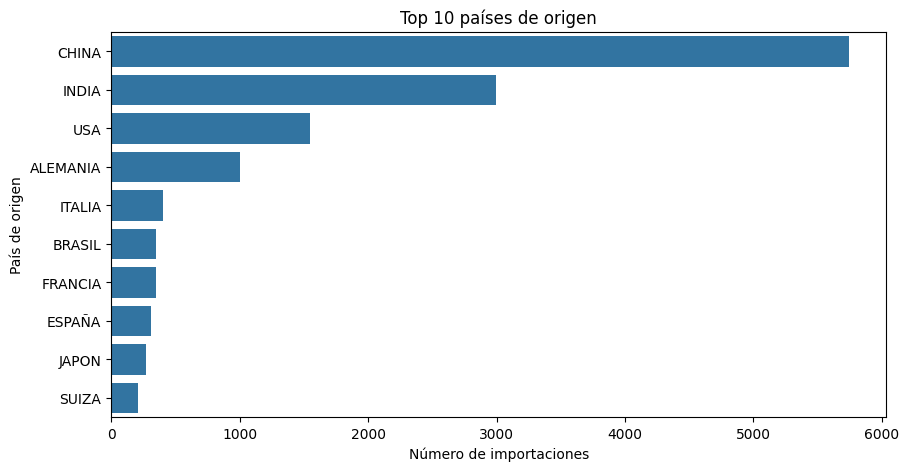

In [31]:
# Crear diccionario de mapeo: código y nombre del país
map_paises = df_paises.set_index("CODIGO")["PAIS"].to_dict()

# Crear columna con el nombre del país
X["PAISCOMPRA_NOMBRE"] = X["PAISORIGEN"].map(map_paises)

# Obtener los 10 países de mayor origen
top_10 = X["PAISCOMPRA_NOMBRE"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(
    x=top_10.values,
    y=top_10.index
)
plt.title("Top 10 países de origen")
plt.xlabel("Número de importaciones")
plt.ylabel("País de origen")
plt.show()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_8876\1615497125.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["VIA_TRANSP_NOMBRE"] = X["VIA_TRANSP"].map(map_transporte)


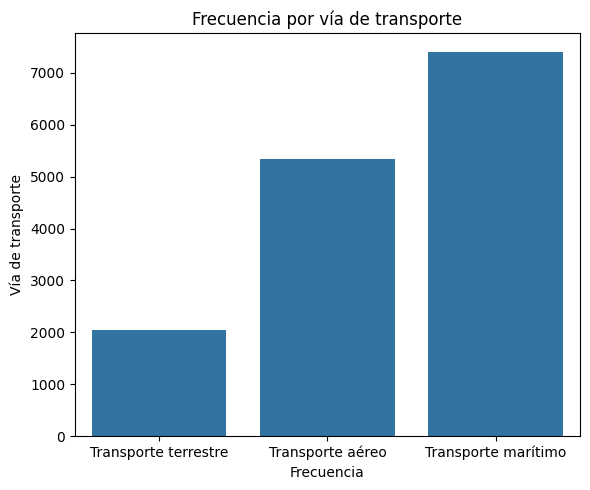

In [42]:
# Diccionario para traducir códigos a nombres reales
map_transporte = {
    1: "Transporte marítimo",
    3: "Transporte terrestre",
    4: "Transporte aéreo"
}

# Crear columna traducida
X["VIA_TRANSP_NOMBRE"] = X["VIA_TRANSP"].map(map_transporte)

# Contar frecuencia por vía de transporte
freq = X["VIA_TRANSP_NOMBRE"].value_counts().sort_values(ascending=True)

# Gráfico
plt.figure(figsize=(6,5))
sns.barplot(y=freq.values, x=freq.index)

plt.title("Frecuencia por vía de transporte")
plt.xlabel("Frecuencia")
plt.ylabel("Vía de transporte")
plt.tight_layout()
plt.show()


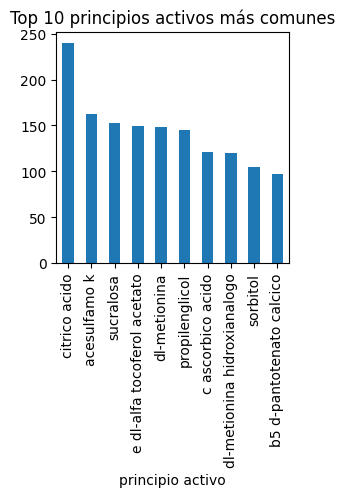

In [49]:
# Distribución por principio activo
y["principio activo"].value_counts().head(10).plot(kind="bar", figsize=(3,3))
plt.title("Top 10 principios activos más comunes")
plt.show()

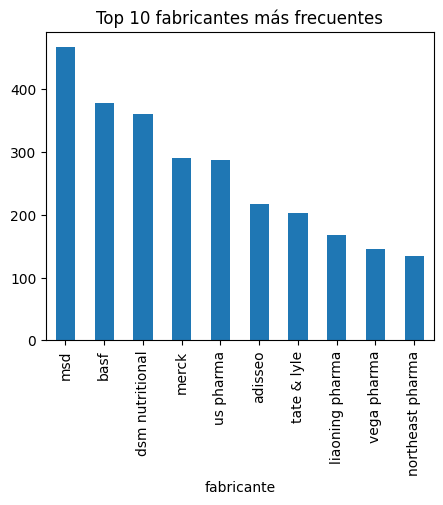

In [52]:
# Distribución por fabricante
y["fabricante"].value_counts().head(10).plot(kind="bar", figsize=(5,4))
plt.title("Top 10 fabricantes más frecuentes")
plt.show()

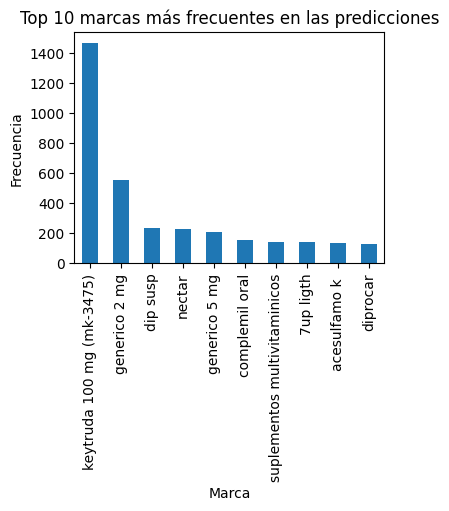

In [54]:
# Marcas de medicamneto más frecuentes en las predicciones
plt.figure(figsize=(8,5))
pred_farma["marca"].value_counts().head(10).plot(kind="bar", figsize=(4,3))
plt.title("Top 10 marcas más frecuentes en las predicciones")
plt.xlabel("Marca")
plt.ylabel("Frecuencia")
plt.show()